<a href="https://colab.research.google.com/github/boddanapurna6-oss/Deep-Learning-skills/blob/main/Skill3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import torch
import torchvision
import matplotlib.pyplot as plt
import time, json
from PIL import Image
from torchvision import transforms
from google.colab import files

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
print("PyTorch:", torch.__version__)

Device: cpu
PyTorch: 2.14.1+cpu


Saving Screenshot 2026-11-13 140639.png to Screenshot 2026-11-13 140639.png


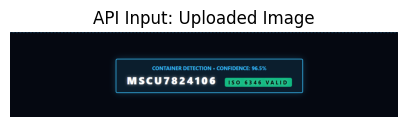

API Request: {'request_id': 'REQ-001', 'filename': 'Screenshot 2026-11-13 140639.png', 'input_type': 'image'}


In [10]:
uploaded = files.upload()

image_path = list(uploaded.keys())[0]
image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(5,5))
plt.imshow(image)
plt.title("API Input: Uploaded Image")
plt.axis("off")
plt.show()

request = {
    "request_id": "REQ-001",
    "filename": image_path,
    "input_type": "image"
}

print("API Request:", request)

Original Image: (1120, 245)
Processed Tensor: torch.Size([1, 3, 224, 224])
Preprocessing Time: 8.07 ms


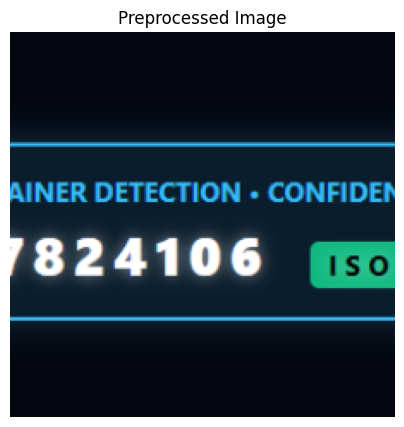

In [11]:
weights = torchvision.models.ResNet18_Weights.DEFAULT

preprocess = weights.transforms()

start = time.time()
input_tensor = preprocess(image).unsqueeze(0).to(device)
preprocess_time = (time.time() - start) * 1000

print("Original Image:", image.size)
print("Processed Tensor:", input_tensor.shape)
print("Preprocessing Time:", round(preprocess_time, 2), "ms")

plt.figure(figsize=(5,5))
plt.imshow(input_tensor.cpu().squeeze().permute(1,2,0).numpy()
           * torch.tensor([0.229,0.224,0.225]).numpy()
           + torch.tensor([0.485,0.456,0.406]).numpy())
plt.title("Preprocessed Image")
plt.axis("off")
plt.show()

In [12]:
model = torchvision.models.resnet18(weights=weights)
model = model.to(device)
model.eval()

if device == "cuda":
    torch.cuda.synchronize()

start = time.time()

with torch.no_grad():
    output = model(input_tensor)
    probabilities = torch.nn.functional.softmax(output, dim=1)

if device == "cuda":
    torch.cuda.synchronize()

inference_time = (time.time() - start) * 1000

confidence, predicted = torch.max(probabilities, 1)

class_name = weights.meta["categories"][predicted.item()]
confidence_score = confidence.item() * 100

print("Predicted Class:", class_name)
print("Confidence:", round(confidence_score, 2), "%")
print("Inference Time:", round(inference_time, 2), "ms")
print("Execution Device:", device)

Predicted Class: digital clock
Confidence: 23.8 %
Inference Time: 82.15 ms
Execution Device: cpu


In [13]:
response = {
    "request_id": request["request_id"],
    "status": "success",
    "prediction": class_name,
    "confidence": round(confidence_score, 2),
    "device": device,
    "preprocessing_ms": round(preprocess_time, 2),
    "inference_ms": round(inference_time, 2)
}

print(json.dumps(response, indent=4))

{
    "request_id": "REQ-001",
    "status": "success",
    "prediction": "digital clock",
    "confidence": 23.8,
    "device": "cpu",
    "preprocessing_ms": 8.07,
    "inference_ms": 82.15
}


Graphical Architecture Representation

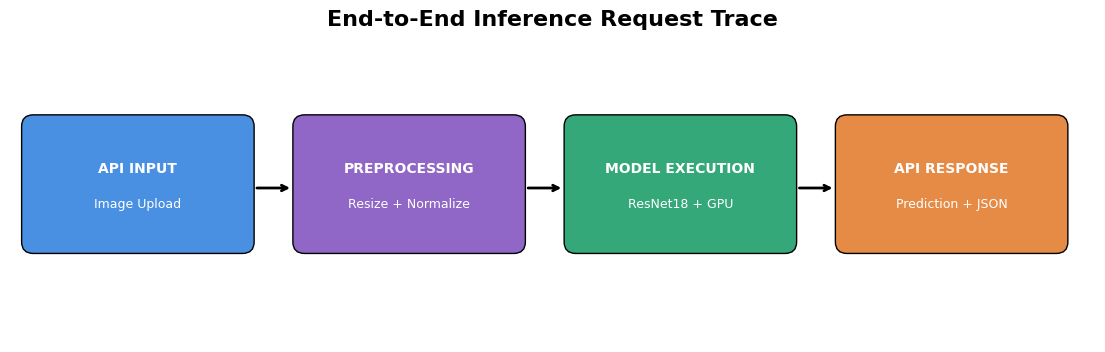

In [14]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(14, 4))
ax.set_xlim(0, 14)
ax.set_ylim(0, 4)
ax.axis("off")

steps = [
    ("API INPUT", "Image Upload"),
    ("PREPROCESSING", "Resize + Normalize"),
    ("MODEL EXECUTION", "ResNet18 + GPU"),
    ("API RESPONSE", "Prediction + JSON")
]

colors = ["#4A90E2", "#9067C6", "#35A879", "#E58B45"]
positions = [0.3, 3.8, 7.3, 10.8]

for i, (title, desc) in enumerate(steps):
    box = FancyBboxPatch(
        (positions[i], 1.3), 2.7, 1.5,
        boxstyle="round,pad=0.15",
        facecolor=colors[i], edgecolor="black"
    )
    ax.add_patch(box)
    ax.text(positions[i]+1.35, 2.2, title,
            ha="center", color="white", weight="bold")
    ax.text(positions[i]+1.35, 1.75, desc,
            ha="center", color="white", fontsize=9)

    if i < 3:
        ax.annotate("", xy=(positions[i+1]-0.15, 2),
                    xytext=(positions[i]+2.85, 2),
                    arrowprops=dict(arrowstyle="->", lw=2))

plt.title("End-to-End Inference Request Trace",
          fontsize=16, weight="bold")
plt.savefig("inference_architecture.png", dpi=200)
plt.show()

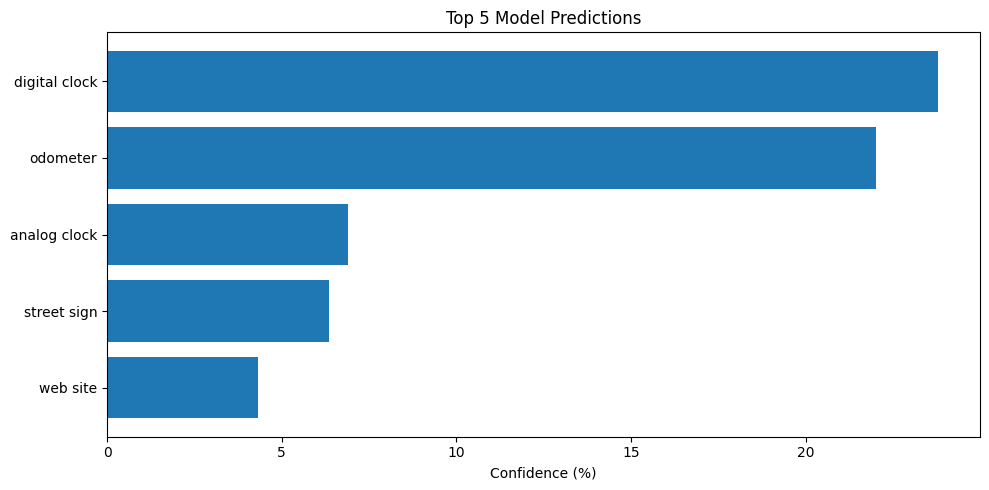

In [15]:
top5 = torch.topk(probabilities[0], 5)

labels = [weights.meta["categories"][i]
          for i in top5.indices.cpu().tolist()]

scores = top5.values.cpu().numpy() * 100

plt.figure(figsize=(10,5))
plt.barh(labels[::-1], scores[::-1])
plt.xlabel("Confidence (%)")
plt.title("Top 5 Model Predictions")
plt.tight_layout()
plt.show()

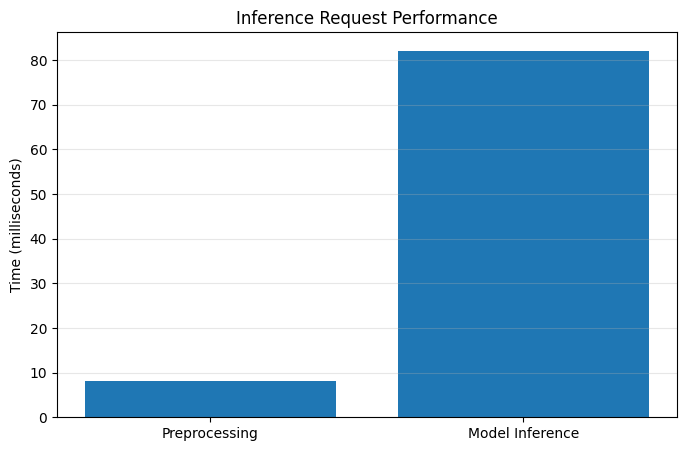

Total Processing Time: 90.23 ms


In [16]:
stages = ["Preprocessing", "Model Inference"]
times = [preprocess_time, inference_time]

plt.figure(figsize=(8,5))
plt.bar(stages, times)
plt.ylabel("Time (milliseconds)")
plt.title("Inference Request Performance")
plt.grid(axis="y", alpha=0.3)
plt.show()

print("Total Processing Time:",
      round(sum(times), 2), "ms")